# 04_07 – Проверка пары по открытым измерениям

Работаем без Trino и аффилиации. Пара 134: CES773, ICAO24 780b33, LFPG, 04.03.2019. Выбрана по доступности публичного снимка, а не случайно; вывод не распространяется автоматически на остальные 146 пар. Обе исходные метки GoA=False.

Два почасовых снимка OpenSky 04–05 UTC уже сохранены. Источник независим от производной таблицы посадок, но использует ту же сеть измерений OpenSky. Сохраняем все исходные значения, включая пропуски и выбросы. [Описание публичного набора](https://opensky-network.org/data/scientific), [определения полей](https://s3.opensky-network.org/data-samples/states/README.txt).

In [1]:
# Загружаем уже сохраненные публичные данные, не скачивая их повторно
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]
          if (p/'europe/data/source/osn23_landings_merged.parquet.gzip').exists())
sys.path.insert(0,str(ROOT/'europe/scripts'))
import check_public_pair as analysis

# Проверяем происхождение и свежесть точек, затем сопоставляем времена записи
raw,event_measurements=analysis.main()
display(event_measurements)

{
  "pair_id": 134,
  "icao24": "780b33",
  "airport": "LFPG",
  "raw_rows": 524,
  "fresh_contact_and_position_rows": 457,
  "maximum_raw_time_gap_seconds": 20.0,
  "early_landing_time": "2019-03-04 04:53:00+00:00",
  "late_landing_time": "2019-03-04 05:13:31+00:00",
  "early_event_geoaltitude_metres": 1524.0000000000002,
  "early_event_vertical_rate_metres_per_second": 4.55168,
  "early_event_onground": false,
  "first_fresh_surface_time": "2019-03-04 05:13:50+00:00",
  "barometric_altitude_above_20000m_rows": 1,
  "barometric_outlier_rule": "Diagnostic display count only; no raw value changed",
  "conclusion": "early landing_time occurs during observed airborne climb; late time close to surface transition",
  "exact_touchdown_time_verified": false,
  "operational_go_around_count_verified": false,
  "C40_geometric_crossing_verified": false,
  "rows_changed": 0,
  "rows_deleted": 0,
  "input_unchanged": true,
  "input_sha256": "ddf11438bab44137242ffcf4da928418e116efd46defce58dc8a388b6

,time,icao24,lat,lon,velocity,heading,vertrate,callsign,onground,alert,...,geoaltitude,lastposupdate,lastcontact,utc,contact_age_seconds,position_age_seconds,fresh_contact_and_position,event,target_utc,time_difference_seconds
0,1551675160,780b33,49.026955,2.566970,84.163101,265.090938,13.65504,CES773,False,False,...,1348.74,1.551675e+09,1.551675e+09,2019-03-04 04:52:40+00:00,0.045,0.248,True,early_first_attempt,2019-03-04 04:52:44+00:00,-4.0
1,1551675180,780b33,49.025620,2.542560,92.408234,265.209869,4.55168,CES773,False,False,...,1524.00,1.551675e+09,1.551675e+09,2019-03-04 04:53:00+00:00,0.012,0.163,True,early_landing,2019-03-04 04:53:00+00:00,0.0
2,1551676410,780b33,49.026901,2.565519,58.316261,265.446232,-1.62560,CES773,False,False,...,190.50,1.551676e+09,1.551676e+09,2019-03-04 05:13:30+00:00,4.394,14.825,True,late_landing,2019-03-04 05:13:31+00:00,-1.0


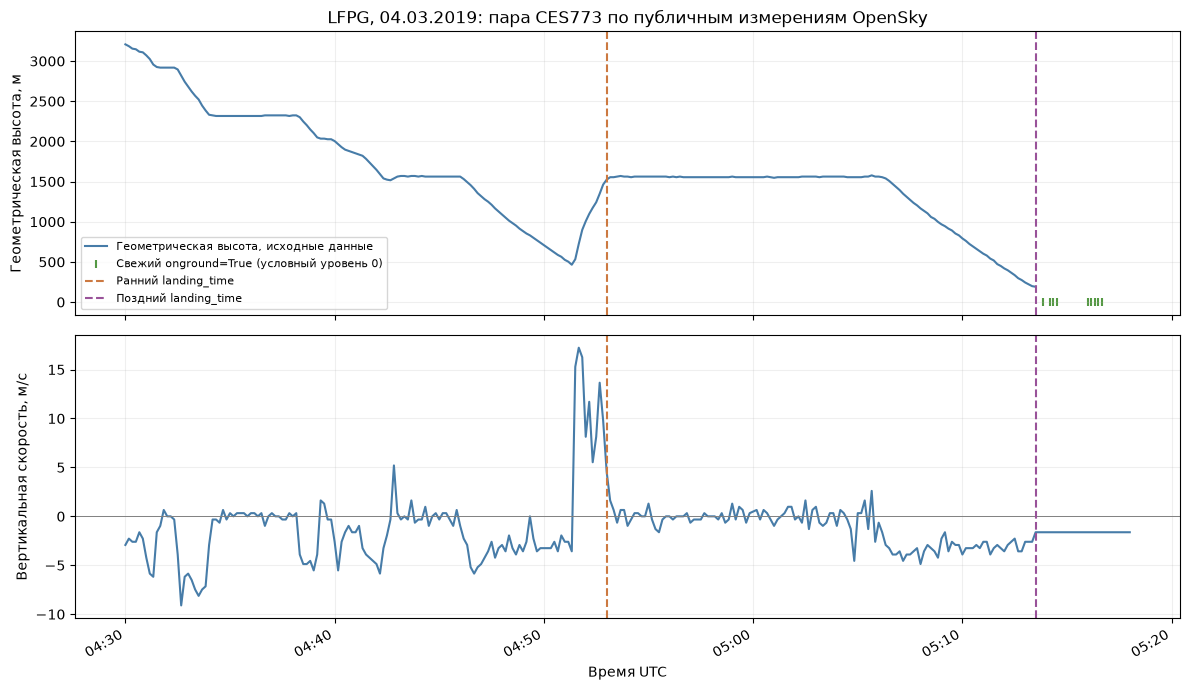

In [2]:
# Показываем снижение, набор высоты и наземные сообщения относительно двух времен
analysis.plot(raw)
plt.show()

## Вывод

В 04:53:00, точно в момент раннего landing_time, свежие измерения показывают onground=False, геометрическую высоту 1 524 м и положительную вертикальную скорость 4,552 м/с. Такое наблюдение не соответствует касанию ВПП в этот момент. После него видны продолжение движения и последующее снижение; первый свежий onground=True – 05:13:50, около позднего landing_time 05:13:31.

Точное время касания и эксплуатационное число уходов не установлены. Ненулевая высота не интерпретируется как высота над аэродромом. Найдено отдельное аномальное значение барометрической высоты около перехода на наземную фазу; оно сохранено и не используется для вывода о наборе.

Раннюю запись нельзя считать независимой подтвержденной посадкой только по landing_time. Поздняя запись согласуется с прибытием, но это не разрешает автоматически удалить раннюю или исправить GoA. Геометрическое совпадение C40 с границей 40 NM в этом шаге не проверено. [Отчет](../../reports/analytical_sample/04_07_review.md).